# ÖKOBAUDAT: input preparation and data checks

This notebook defines an input schema for environmental product information and checks the availability of source measurements. The repository currently contains a source reference and an empty template; environmental observations have not been imported.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "datasets/dtd/source.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside a cloned Fitwell-AI repository")
plt.rcParams.update({"figure.facecolor": "#f5f1ea", "axes.facecolor": "#f5f1ea", "font.size": 11})
print("Repository:", ROOT.name)


Repository: Fitwell-AI


In [2]:
folder = ROOT / "datasets/oekobaudat"
template = pd.read_csv(folder / "environmental_records_template.csv")
print("Template columns:", list(template.columns))
print("Template observations:", len(template))
input_path = folder / "environmental_records.csv"
records = pd.read_csv(input_path, sep=";", dtype=str, encoding="cp1252") if input_path.exists() else None
if records is None:
    print("No official export found. See the cleaned table below.")
else:
    print("Official export rows:", len(records))
    print(records[["Name (en)", "Kategorie (en)", "Typ", "Modul"]].head().to_string(index=False))


Template columns: ['source_record_id', 'material_name', 'reference_unit', 'lifecycle_module', 'indicator', 'value', 'unit', 'source_url']
Template observations: 0
Official export rows: 44973
    Name (en)                                   Kategorie (en)              Typ Modul
FOAMGLAS® T4+ 'Insulation materials' / 'Foam glass' / 'Panels' specific dataset A1-A3
FOAMGLAS® T4+ 'Insulation materials' / 'Foam glass' / 'Panels' specific dataset    A4
FOAMGLAS® T4+ 'Insulation materials' / 'Foam glass' / 'Panels' specific dataset    A5
FOAMGLAS® T4+ 'Insulation materials' / 'Foam glass' / 'Panels' specific dataset    C1
FOAMGLAS® T4+ 'Insulation materials' / 'Foam glass' / 'Panels' specific dataset    C2


In [3]:
if records is not None and not records.empty:
    print("The official export is available. The cleaned records and graphs are shown below.")
else:
    print("Run clean_oekobaudat.py before reviewing the cleaned records.")


The official export is available. The cleaned records and graphs are shown below.


## Raw ÖKOBAUDAT table preview


In [4]:
display(records.head(20))


,UUID,Version,Name (de),Name (en),Kategorie (original),Kategorie (en),Konformitaet,Hintergrunddatenbank(en),Laenderkennung,Typ,...,TMR fossile,TMR metals,TMR minerals,TMR forestry,TMR agriculture,TMR fisheries,TMR abiotic subtotal,TMR biotic subtotal,TMR total,Unnamed: 99
0,c93da4c3-94c9-4c86-b092-610cf1cf012f,00.10.000,FOAMGLAS® T4+,FOAMGLAS® T4+,'Dämmstoffe' / 'Schaumglas' / 'Platten','Insulation materials' / 'Foam glass' / 'Panels','DIN EN 15804+A2' / 'ISO 14025','GaBi database (28d74cc0-db8b-4d7e-bc44-5f6d56...,RER,specific dataset,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,c93da4c3-94c9-4c86-b092-610cf1cf012f,00.10.000,FOAMGLAS® T4+,FOAMGLAS® T4+,'Dämmstoffe' / 'Schaumglas' / 'Platten','Insulation materials' / 'Foam glass' / 'Panels','DIN EN 15804+A2' / 'ISO 14025','GaBi database (28d74cc0-db8b-4d7e-bc44-5f6d56...,RER,specific dataset,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,c93da4c3-94c9-4c86-b092-610cf1cf012f,00.10.000,FOAMGLAS® T4+,FOAMGLAS® T4+,'Dämmstoffe' / 'Schaumglas' / 'Platten','Insulation materials' / 'Foam glass' / 'Panels','DIN EN 15804+A2' / 'ISO 14025','GaBi database (28d74cc0-db8b-4d7e-bc44-5f6d56...,RER,specific dataset,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,c93da4c3-94c9-4c86-b092-610cf1cf012f,00.10.000,FOAMGLAS® T4+,FOAMGLAS® T4+,'Dämmstoffe' / 'Schaumglas' / 'Platten','Insulation materials' / 'Foam glass' / 'Panels','DIN EN 15804+A2' / 'ISO 14025','GaBi database (28d74cc0-db8b-4d7e-bc44-5f6d56...,RER,specific dataset,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,c93da4c3-94c9-4c86-b092-610cf1cf012f,00.10.000,FOAMGLAS® T4+,FOAMGLAS® T4+,'Dämmstoffe' / 'Schaumglas' / 'Platten','Insulation materials' / 'Foam glass' / 'Panels','DIN EN 15804+A2' / 'ISO 14025','GaBi database (28d74cc0-db8b-4d7e-bc44-5f6d56...,RER,specific dataset,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,c93da4c3-94c9-4c86-b092-610cf1cf012f,00.10.000,FOAMGLAS® T4+,FOAMGLAS® T4+,'Dämmstoffe' / 'Schaumglas' / 'Platten','Insulation materials' / 'Foam glass' / 'Panels','DIN EN 15804+A2' / 'ISO 14025','GaBi database (28d74cc0-db8b-4d7e-bc44-5f6d56...,RER,specific dataset,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,c93da4c3-94c9-4c86-b092-610cf1cf012f,00.10.000,FOAMGLAS® T4+,FOAMGLAS® T4+,'Dämmstoffe' / 'Schaumglas' / 'Platten','Insulation materials' / 'Foam glass' / 'Panels','DIN EN 15804+A2' / 'ISO 14025','GaBi database (28d74cc0-db8b-4d7e-bc44-5f6d56...,RER,specific dataset,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,c93da4c3-94c9-4c86-b092-610cf1cf012f,00.10.000,FOAMGLAS® T4+,FOAMGLAS® T4+,'Dämmstoffe' / 'Schaumglas' / 'Platten','Insulation materials' / 'Foam glass' / 'Panels','DIN EN 15804+A2' / 'ISO 14025','GaBi database (28d74cc0-db8b-4d7e-bc44-5f6d56...,RER,specific dataset,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,c93da4c3-94c9-4c86-b092-610cf1cf012f,00.10.000,FOAMGLAS® T4+,FOAMGLAS® T4+,'Dämmstoffe' / 'Schaumglas' / 'Platten','Insulation materials' / 'Foam glass' / 'Panels','DIN EN 15804+A2' / 'ISO 14025','GaBi database (28d74cc0-db8b-4d7e-bc44-5f6d56...,RER,specific dataset,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,c93da4c3-94c9-4c86-b092-610cf1cf012f,00.10.000,FOAMGLAS® T4+,FOAMGLAS® T4+,'Dämmstoffe' / 'Schaumglas' / 'Platten','Insulation materials' / 'Foam glass' / 'Panels','DIN EN 15804+A2' / 'ISO 14025','GaBi database (28d74cc0-db8b-4d7e-bc44-5f6d56...,RER,specific dataset,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Interpretation

The template defines required fields for a verified source export. Reference units, lifecycle modules, indicators and measurement units must be retained. Comparisons require compatible units and system boundaries. XML conversion, environmental estimation and visual-recognition training are outside the scope of this notebook.

# ÖKOBAUDAT cleaning and quality review

This notebook documents the research cleaning of the official ÖKOBAUDAT 2024-II CSV export. It keeps source identifiers, lifecycle modules, units and source URLs. It removes incomplete environmental records and duplicate rows, then visualizes the cleaned dataset.

In [5]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'datasets/oekobaudat').exists():
    ROOT = ROOT.parent
FOLDER = ROOT / 'datasets/oekobaudat'
cleaned = pd.read_csv(FOLDER / 'environmental_records_clean.csv')
with (FOLDER / 'analysis/cleaning_report.json').open(encoding='utf-8') as f:
    report = json.load(f)
print('Source:', report['source'])
print(f"Rows before cleaning: {report['rows_before_cleaning']:,}")
print(f"Rows after cleaning:  {report['rows_after_cleaning']:,}")
print(f"Missing/invalid rows removed: {report['missing_required_values_removed']:,}")
print(f"Duplicate rows removed: {report['duplicate_rows_removed']:,}")

Source: ÖKOBAUDAT 2024-II CSV export
Rows before cleaning: 44,973
Rows after cleaning:  44,029
Missing/invalid rows removed: 777
Duplicate rows removed: 167


## Cleaned table preview

In [6]:
display(cleaned.head(20))
display(cleaned.describe(include='all').transpose().head(12))

,UUID,Version,Name (en),material_category,Typ,Bezugseinheit,Modul,gwp_total_kg_co2e,URL
0,c93da4c3-94c9-4c86-b092-610cf1cf012f,00.10.000,FOAMGLAS® T4+,Insulation materials,specific dataset,kg,A1-A3,1.430000,https://www.oekobaudat.de/OEKOBAU.DAT/resource...
1,c93da4c3-94c9-4c86-b092-610cf1cf012f,00.10.000,FOAMGLAS® T4+,Insulation materials,specific dataset,kg,A4,0.029600,https://www.oekobaudat.de/OEKOBAU.DAT/resource...
2,c93da4c3-94c9-4c86-b092-610cf1cf012f,00.10.000,FOAMGLAS® T4+,Insulation materials,specific dataset,kg,A5,0.121100,https://www.oekobaudat.de/OEKOBAU.DAT/resource...
3,c93da4c3-94c9-4c86-b092-610cf1cf012f,00.10.000,FOAMGLAS® T4+,Insulation materials,specific dataset,kg,C1,0.000616,https://www.oekobaudat.de/OEKOBAU.DAT/resource...
4,c93da4c3-94c9-4c86-b092-610cf1cf012f,00.10.000,FOAMGLAS® T4+,Insulation materials,specific dataset,kg,C2,0.002350,https://www.oekobaudat.de/OEKOBAU.DAT/resource...
5,c93da4c3-94c9-4c86-b092-610cf1cf012f,00.10.000,FOAMGLAS® T4+,Insulation materials,specific dataset,kg,C3,0.000000,https://www.oekobaudat.de/OEKOBAU.DAT/resource...
6,c93da4c3-94c9-4c86-b092-610cf1cf012f,00.10.000,FOAMGLAS® T4+,Insulation materials,specific dataset,kg,C3,0.002410,https://www.oekobaudat.de/OEKOBAU.DAT/resource...
7,c93da4c3-94c9-4c86-b092-610cf1cf012f,00.10.000,FOAMGLAS® T4+,Insulation materials,specific dataset,kg,C4,0.015300,https://www.oekobaudat.de/OEKOBAU.DAT/resource...
8,c93da4c3-94c9-4c86-b092-610cf1cf012f,00.10.000,FOAMGLAS® T4+,Insulation materials,specific dataset,kg,D,-1.430000,https://www.oekobaudat.de/OEKOBAU.DAT/resource...
9,c93da4c3-94c9-4c86-b092-610cf1cf012f,00.10.000,FOAMGLAS® T4+,Insulation materials,specific dataset,kg,D,-0.177300,https://www.oekobaudat.de/OEKOBAU.DAT/resource...


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UUID,44029,4298,b144ce25-34af-437d-b324-1dfdcb20a889,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Version,44029,133,12.00.000,19695,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Name (en),44029,4244,TRM-Tiroler Rohre Piling systems Typ 118 - 10.6,126,NaN,NaN,NaN,NaN,NaN,NaN,NaN
material_category,44029,11,Building service engineering,23601,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Typ,44029,5,average dataset,27579,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Bezugseinheit,44029,8,pcs.,24652,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Modul,44029,18,D,4332,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gwp_total_kg_co2e,44029.0,NaN,NaN,NaN,264.49059,25287.831498,-433365.89412,0.0,0.006206,1.27,3707035.319924
URL,44029,4298,https://www.oekobaudat.de/OEKOBAU.DAT/resource...,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Cleaning graphs

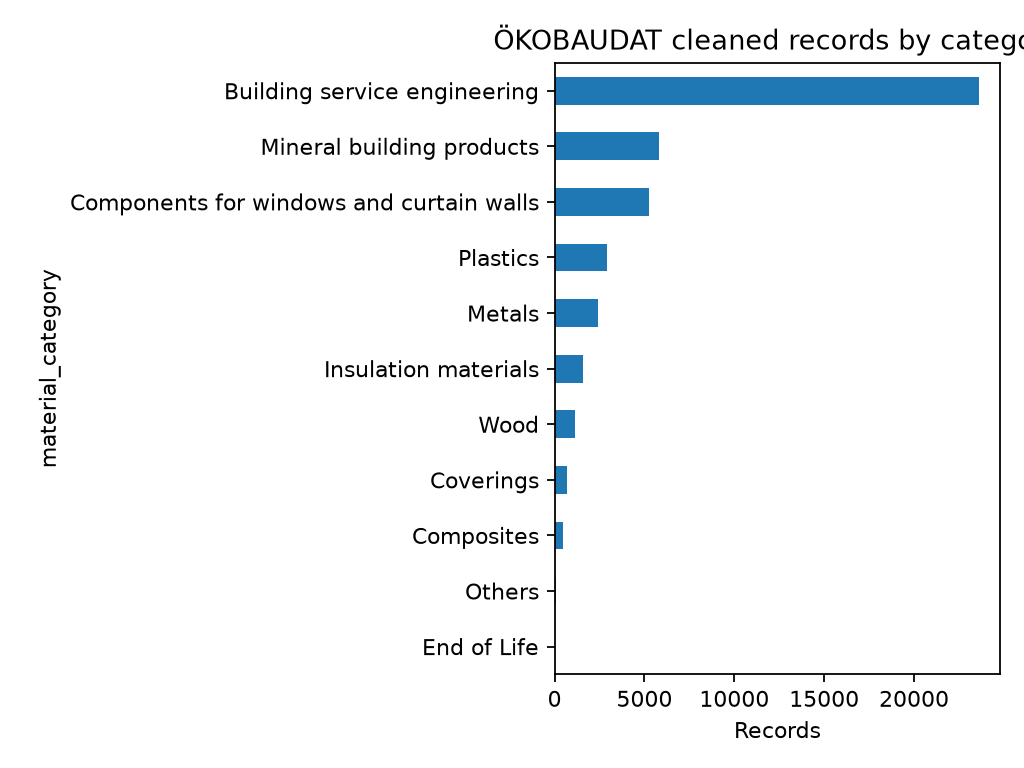

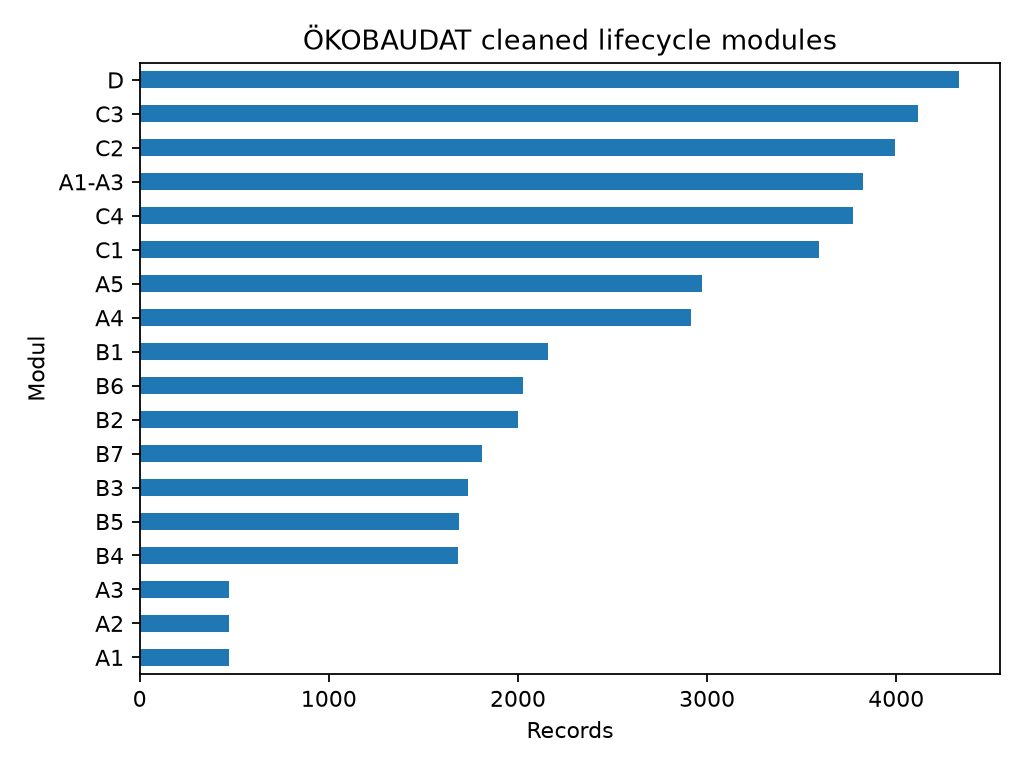

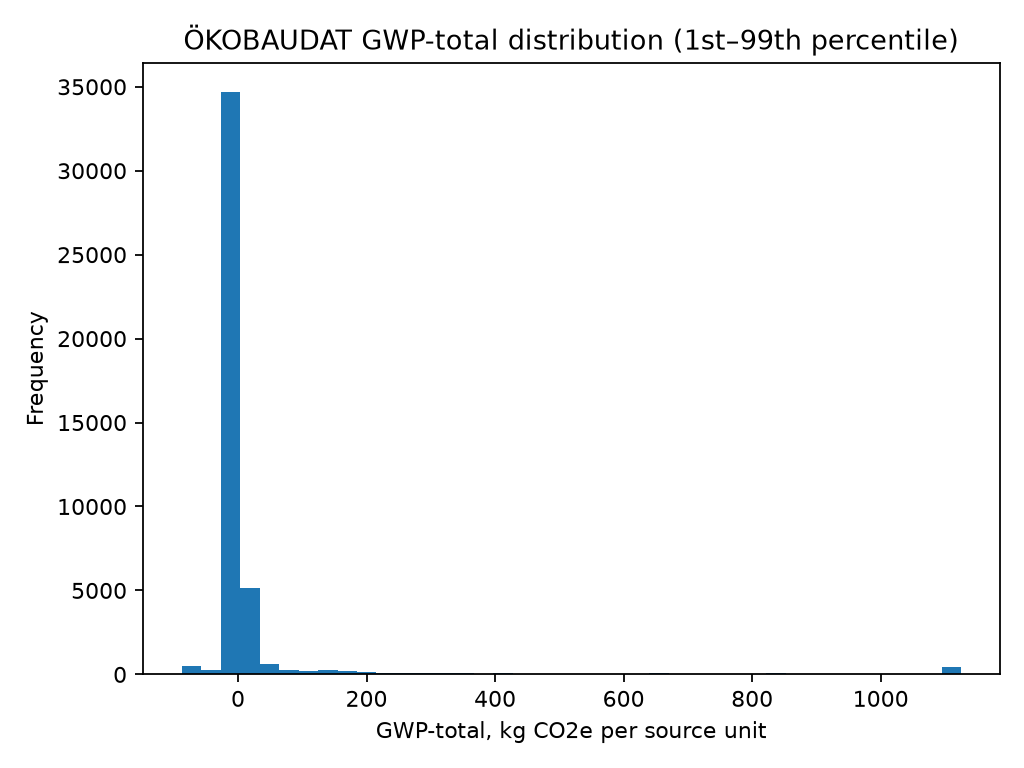

In [7]:
display(Image(filename=str(FOLDER / 'analysis/records_by_category.png')))
display(Image(filename=str(FOLDER / 'analysis/records_by_lifecycle_module.png')))
display(Image(filename=str(FOLDER / 'analysis/gwp_total_distribution.png')))

## Interpretation

The cleaned table is a source-preserving environmental reference. GWP-total values are reported per source unit and are not directly comparable across different units such as kg, m² and m³. A project-level carbon assessment still needs the selected product, quantity, application and complete lifecycle modules.